In [2]:
import numpy as np
import matplotlib.pyplot as plt
 
# ------------------------------------------------------------------ data
# Measured Heise-gauge pressures
P_N2 = np.array([1809, 1499, 1191, 951, 762, 610, 489, 390, 313, 250, 199, 160, 127, 102, 81, 64, 51, 41], float)
P_AR = np.array([1741, 1396, 1119, 905, 730, 588, 472, 380, 303, 244, 193, 156, 124, 99, 79, 64, 51, 40], float)
P_CO2 = np.array([788, 695, 598, 513, 433, 360, 297, 244, 197, 160, 130, 104, 83, 67, 55, 43], float)
 
# N2 densities (mol/L) 
RHO_N2 = np.array([4.9626, 4.1433, 3.3096, 2.6496, 2.1254, 1.7019, 1.3641, 1.0875, 0.87242, 0.6965,
                   0.55417, 0.4454, 0.35341, 0.28377, 0.22529, 0.17797, 0.1418, 0.11398])
 
# Temperatures 
T_N2_DATA = 25.3 + 273.15            # N2 run
T_N2_GRAPH = 300.0                   # N2 penultimate graph (checkpoint spec)
T_AR = 25.3 + 273.15
T_CO2 = (25.3 + 25.2) / 2 + 273.15   # average of start and end of run
 
# Literature virial coefficients
LIT = {
    "N2": (-4.53, 1375),     # 300 K, lab manual table (NIST WebBook)
    "Ar": (-15.49, 1061),    # 298.45 K, NIST reference EOS (Tegeler et al. 1999)
    "CO2": (-122.78, 4743),  # 298.40 K, NIST reference EOS (Span & Wagner 1996)
}
 
# Critical constants (NIST WebBook):
CRIT = {"N2": (126.192, 33.958), "Ar": (150.687, 48.630), "CO2": (304.128, 73.773)}
 


In [3]:
R_SI = 8.314462618                 # J/(mol K)
PA_PER_PSI = 6894.757              # lab manual Eq. 14
R_BAR = R_SI / 100                 # L bar/(mol K)
R_PSI_CC = R_SI * 1e6 / PA_PER_PSI # psi cm3/(mol K)
PSI_PER_BAR = 1e5 / PA_PER_PSI


In [4]:
def fit_r(rho, first_k=2):
    """Least-squares fit of ln(rho_k) = ln(alpha) + beta k (Eq. 20)"""
    k = np.arange(1, len(rho) + 1)
    use = k >= first_k                       # k = 1 excluded (lies 5% off the series)
    beta, ln_alpha = np.polyfit(k[use], np.log(rho[use]), 1)
    return np.exp(ln_alpha), beta, np.exp(beta)
 
 
def fit_virial(P, T, r):
    """P_k = c1 x + c2 x^2 + c3 x^3 with x = r^k, no constant term (Eq. 22) -> B, C, alpha."""
    x = r ** np.arange(1, len(P) + 1)
    X = np.column_stack([x, x**2, x**3])
    c1, c2, c3 = np.linalg.lstsq(X, P, rcond=None)[0]
    RT = R_PSI_CC * T                         # psi cm3/mol
    B = RT * c2 / c1**2                       # cm3/mol      (Eq. 26)
    C = RT**2 * c3 / c1**3                    # cm6/mol2     (Eq. 27)
    alpha = c1 / RT * 1000                    # mol/L        (Eq. 25)
    return B, C, alpha
 
 
def vdw_ab(gas):
    """van der Waals a (bar L2/mol2) and b (L/mol) from critical constants."""
    Tc, Pc = CRIT[gas]
    return 27 * R_BAR**2 * Tc**2 / (64 * Pc), R_BAR * Tc / (8 * Pc)
 
 
alpha_N2, beta_N2, r = fit_r(RHO_N2)
B_AR, C_AR, alpha_AR = fit_virial(P_AR, T_AR, r)
B_CO2, C_CO2, alpha_CO2 = fit_virial(P_CO2, T_CO2, r)
 
print(f"r = {r:.5f}   (alpha = {alpha_N2:.4f} M, beta = {beta_N2:.5f})")
print(f"Ar : B = {B_AR:.1f} cm3/mol,  C = {C_AR:.0f} cm6/mol2")
print(f"CO2: B = {B_CO2:.1f} cm3/mol,  C = {C_CO2:.0f} cm6/mol2")
for g in CRIT:
    a, b = vdw_ab(g)
    print(f"{g:>3}: a = {a:.3f} bar L2/mol2,  b = {b:.4f} L/mol")


r = 0.79875   (alpha = 6.5433 M, beta = -0.22470)
Ar : B = -27.2 cm3/mol,  C = 2579 cm6/mol2
CO2: B = -137.6 cm3/mol,  C = 7908 cm6/mol2
 N2: a = 1.368 bar L2/mol2,  b = 0.0386 L/mol
 Ar: a = 1.362 bar L2/mol2,  b = 0.0322 L/mol
CO2: a = 3.657 bar L2/mol2,  b = 0.0428 L/mol


In [5]:
RHO = np.linspace(1e-4, 6, 400)  # mol/L
 
 
def P_ideal(T):
    return R_BAR * T * RHO * PSI_PER_BAR
 
 
def P_vdw(T, a, b):
    return (R_BAR * T * RHO / (1 - b * RHO) - a * RHO**2) * PSI_PER_BAR
 
 
def P_virial(T, B, C):
    return R_BAR * T * RHO * (1 + B / 1e3 * RHO + C / 1e6 * RHO**2) * PSI_PER_BAR
 


In [6]:
INK, INK2 = "#0b0b0b", "#52514e"
RED, BLUE, YELLOW, GREEN = "#FF0000", "#0000FF", "#FFFF00", "#008000"

In [7]:
def penultimate(title, gas, T, B_lit, C_lit, P_exp, rho_exp, B_exp=None, C_exp=None):
    a, b = vdw_ab(gas)
    fig, ax = plt.subplots(figsize=(6.5, 4.9))
    ax.plot(P_ideal(T), RHO, ls=(0, (1.5, 2)), color=RED, lw=1.8, label="Ideal gas")
    ax.plot(P_vdw(T, a, b), RHO, ls=(0, (6, 2, 1.5, 2)), color=BLUE, lw=1.8, label="van der Waals")
    ax.plot(P_virial(T, B_lit, C_lit), RHO, ls=(0, (5, 2.5)), color=YELLOW, lw=1.8,
            label="Virial, literature $B$, $C$")
    if B_exp is not None:
        ax.plot(P_virial(T, B_exp, C_exp), RHO, color=GREEN, lw=1.8, label="Virial, this work's $B$, $C$")
    ax.plot(P_exp, rho_exp, "o", ms=6, mfc=INK, mec="white", mew=0.8, zorder=4,
            label=r"Experiment, $\rho_k = \alpha r^k$")
 
    ax.set_ylim(0, 6)
    xmax = max(P_ideal(T).max(), np.nanmax(P_vdw(T, a, b)), P_virial(T, B_lit, C_lit).max())
    ax.set_xlim(0, xmax * 1.02)
    ax.set_xlabel("Pressure, $P$ (psi)")
    ax.set_ylabel(r"Density, $\rho$ (mol L$^{-1}$)")
    ax.set_title(title, fontsize=13, color=INK, pad=10)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(which="both", top=False, right=False)
    ax.legend(loc="upper left", handlelength=2.6)
    


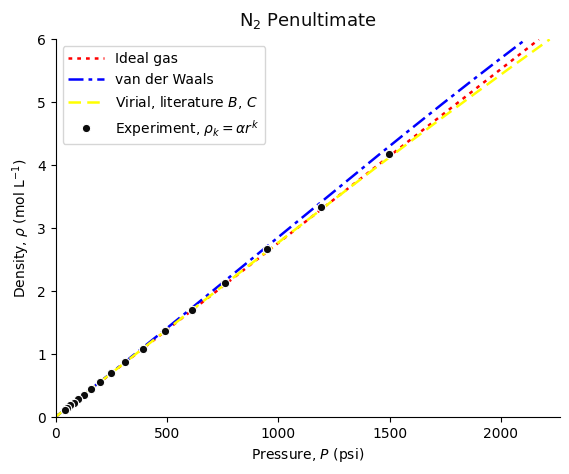

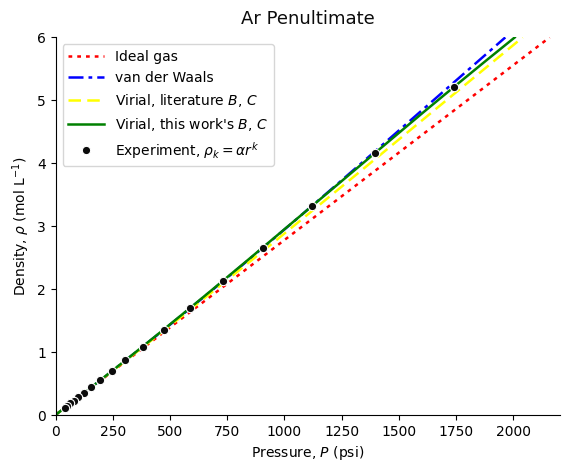

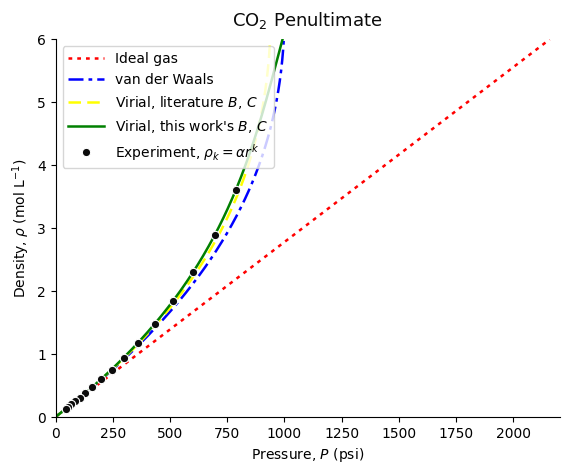

In [8]:
k_N2 = np.arange(1, len(P_N2) + 1)
rho_N2_exp = alpha_N2 * r**k_N2
penultimate("N$_2$ Penultimate", "N2", T_N2_GRAPH, *LIT["N2"],
            P_N2[1:], rho_N2_exp[1:])
 
rho_AR_exp = alpha_AR * r ** np.arange(1, len(P_AR) + 1)
penultimate("Ar Penultimate", "Ar", T_AR, *LIT["Ar"], P_AR, rho_AR_exp,
            B_exp=B_AR, C_exp=C_AR)
 
rho_CO2_exp = alpha_CO2 * r ** np.arange(1, len(P_CO2) + 1)
penultimate("CO$_2$ Penultimate", "CO2", T_CO2, *LIT["CO2"], P_CO2, rho_CO2_exp,
            B_exp=B_CO2, C_exp=C_CO2)
 
plt.show()
 
